### 0.1 Dependencies

In [1]:
import sys, subprocess

def pip_install(pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

# transformers>=4.46 required: eval_strategy + processing_class were introduced in 4.46.
pip_install([
    "transformers>=4.46,<5",
    "datasets>=3.0",
    "accelerate>=0.34",
    "scipy>=1.11",
])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


### 0.2 Imports & Global Configuration (single source of truth for the environment)

In [2]:
import os, re, json, math, time, random, hashlib, shutil, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset as TorchDataset

from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, set_seed as hf_set_seed,
)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score, precision_recall_fscore_support, matthews_corrcoef,
    balanced_accuracy_score, confusion_matrix, classification_report,
)
from scipy import stats

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 110

# ---- Environment contract: the ONLY place run mode is decided ---------------
SMOKE_TEST = False   # True = tiny data + tiny model, CPU fast pass (~2 min)

PRISM_ID  = "pankajbiswas6/prism-hinglish-hate-speech"
MEHATE_REPO = "l3cube-pune/MarathiNLP"          # GitHub repo, CSV fetched at HEAD SHA
MEHATE_CSV  = "MeEval/L3Cube-MeHate/codemix-hate-small-test.csv"

SEEDS = [42, 43, 44]
TINY_MODEL = "sshleifer/tiny-distilroberta-base"
MODELS = {
    "hing-roberta": "l3cube-pune/hing-roberta",
    "muril":        "google/muril-base-cased",
    "xlm-roberta":  "xlm-roberta-base",
}
if SMOKE_TEST:
    MODELS = {k: TINY_MODEL for k in MODELS}

MAX_LEN     = 128 if not SMOKE_TEST else 32
NUM_EPOCHS  = 3   if not SMOKE_TEST else 1
BATCH_SIZE  = 32  if not SMOKE_TEST else 4
BOOTSTRAP_N = 1_000 if not SMOKE_TEST else 100
SMOKE_N     = 200
LR, WEIGHT_DECAY, WARMUP_RATIO = 2e-5, 0.01, 0.1   # named, not magic

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./kaggle_working")
RESULTS_DIR, FIGURES_DIR, PREDS_DIR = WORK_DIR/"results", WORK_DIR/"figures", WORK_DIR/"preds"
for d in (RESULTS_DIR, FIGURES_DIR, PREDS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Fail fast: the full run is impossible on CPU and would silently drop fp16.
if not SMOKE_TEST:
    assert torch.cuda.is_available(), (
        "GPU required: set Accelerator to 'GPU T4 x2' (or P100) in notebook settings. "
        "For a CPU pass, set SMOKE_TEST = True in section 0.2.")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"SMOKE_TEST = {SMOKE_TEST} | Device = {DEVICE} | Work dir = {WORK_DIR.resolve()}")

I0000 00:00:1793774814.183444      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


SMOKE_TEST = False | Device = cuda | Work dir = /kaggle/working


### 0.3 Reproducibility helpers

In [3]:
def set_seed(seed: int) -> None:
    """Seed python, numpy and torch (incl. CUDA). Note: with fp16 + cuDNN this is
    reproducible-in-practice, not bit-exact; `full_determinism=True` would cost speed."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

ALL_SEED_RESULTS = []   # one row per (model, seed, split)
PER_CLASS_RESULTS = []  # per-class P/R/F1 rows
COSTS = []              # params / train time / ms-per-item per (model, seed)
THRESH_CURVES = {}      # (model_key, seed) -> (thresholds, val macro-F1 curve)
LOG_HISTORY = {}        # (model_key, seed) -> trainer.state.log_history
TRAINED = {}            # (model_key, seed=SEEDS[0]) -> artifacts needed in sections 6-7

print("Reproducibility helpers ready.")

Reproducibility helpers ready.


## 1. Data Acquisition & De-identification

### 1.1 Load PRISM at a pinned revision, validate against the card

In [4]:
# Pin the exact upstream revision so `EXPECTED` row counts cannot drift out from under us.
PRISM_SHA = HfApi().dataset_info(PRISM_ID).sha
print(f"PRISM revision (pinned): {PRISM_SHA}")
raw = load_dataset(PRISM_ID, revision=PRISM_SHA)
available = list(raw.keys())
print("Available splits:", available)

def pick_split(names, wanted):
    # Map a canonical name (train/val/test) onto whatever the repo calls it.
    aliases = {"train": ["train"], "val": ["val", "validation", "dev", "valid"], "test": ["test"]}[wanted]
    for a in aliases:
        if a in names:
            return a
    raise ValueError(f"No split matching {wanted!r} in {names}")

SPLIT_MAP = {k: pick_split(available, k) for k in ("train", "val", "test")}
print("Split map:", SPLIT_MAP)

def to_frame(split_key):
    df = raw[SPLIT_MAP[split_key]].to_pandas()
    df = df.rename(columns={"language": "lang"})   # defensive rename
    need = {"text", "label", "lang"}
    missing = need - set(df.columns)
    assert not missing, f"PRISM {split_key}: missing columns {missing}"
    df = df[["text", "label", "lang"]].copy()
    df["text"] = df["text"].astype(str)
    df["label"] = df["label"].astype(int)
    return df

if SMOKE_TEST:
    prism = {k: to_frame(k).head(SMOKE_N).reset_index(drop=True) for k in ("train", "val", "test")}
else:
    prism = {k: to_frame(k).reset_index(drop=True) for k in ("train", "val", "test")}

EXPECTED = {"train": 17_704, "val": 2_950, "test": 8_852}   # verified against revision above
if not SMOKE_TEST:
    for k, n in EXPECTED.items():
        assert len(prism[k]) == n, f"PRISM {k}: {len(prism[k])} rows, expected {n}"
print("PRISM split sizes:", {k: len(v) for k, v in prism.items()})
for k, df in prism.items():
    print(f"  {k:5s} label balance: {df['label'].value_counts(normalize=True).round(3).to_dict()}")

PRISM revision (pinned): b27f83ebc11ccda115608d9ca6be0ec7cfa5b990


README.md: 0.00B [00:00, ?B/s]

train.csv: 0.00B [00:00, ?B/s]

val.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Available splits: ['train', 'validation', 'test']
Split map: {'train': 'train', 'val': 'validation', 'test': 'test'}
PRISM split sizes: {'train': 17704, 'val': 2950, 'test': 8852}
  train label balance: {0: 0.535, 1: 0.465}
  val   label balance: {0: 0.536, 1: 0.464}
  test  label balance: {0: 0.535, 1: 0.465}


### 1.2 De-identification — handles, URLs, emails, phones, PII-safe elongation collapse

In [5]:
URL_RE    = re.compile(r"https?://\S+|www\.\S+")
EMAIL_RE  = re.compile(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}")
PHONE_RE  = re.compile(r"(?:\+?\d[\d\s\-()]{7,}\d)")          # >= 8 digits total
USER_RE   = re.compile(r"@\w+")
LONG_RUN  = re.compile(r"([A-Za-z\u0900-\u097F])\1{3,}")       # letters only: 'soooo'->'soo'

def deidentify(text: str) -> str:
    t = URL_RE.sub("<URL>", text)
    t = EMAIL_RE.sub("<EMAIL>", t)
    t = PHONE_RE.sub("<PHONE>", t)
    t = USER_RE.sub("<USER>", t)
    t = LONG_RUN.sub(r"\1\1", t)
    return t.strip()

for name, df in prism.items():
    prism[name]["text"] = df["text"].map(deidentify)

sample = prism["train"].loc[prism["train"]["text"].str.contains("<USER>|<URL>|<EMAIL>|<PHONE>"), "text"].head(3)
print("De-identified samples:")
for s in sample:
    print("  •", s[:110])

De-identified samples:
  • Socha tha <USER> sath degi par guilt hai isme. Help me help rape victims. …
  • K<USER> ye hai asli. 9 saal ki bacchi se rape karne wale k chamche dusro ko esa nahi bolte
  • <USER> kyaa kiya hai delhi me ab tak?Camera lgawaya so that rape hote huye dekh sko?Rape Rokne par dhyaan lgao


### 1.3 Persist the processed splits (checksummed, reproducible)

In [6]:
def sha256_of_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()

for k, df in prism.items():
    out = RESULTS_DIR / f"prism_{k}.csv"
    df.to_csv(out, index=False)
    print(f"{out.name:20s} rows={len(df):6d}  sha256={sha256_of_file(out)[:16]}…")

DATA_CARD = {
    "dataset": PRISM_ID, "revision_sha": PRISM_SHA, "licence": "MIT",
    "splits": {k: len(v) for k, v in prism.items()},
    "smoke_test": SMOKE_TEST,
    "deidentification": "@handle-><USER>, URL-><URL>, EMAIL-><EMAIL>, PHONE-><PHONE>, "
                        "letter elongation normalised, emojis kept",
    "pii_note": "Regex-based; names in plain text are NOT removed. Stated as such in the report.",
}
(RESULTS_DIR / "data_card.json").write_text(json.dumps(DATA_CARD, indent=2))
print("data_card.json written (revision pinned).")

prism_train.csv      rows= 17704  sha256=6a9c1f76e7f573bc…
prism_val.csv        rows=  2950  sha256=af8693a47d5d911b…
prism_test.csv       rows=  8852  sha256=febf6b13eaf564fe…
data_card.json written (revision pinned).


## 2. Exploratory Data Analysis

### 2.1 Class balance per language

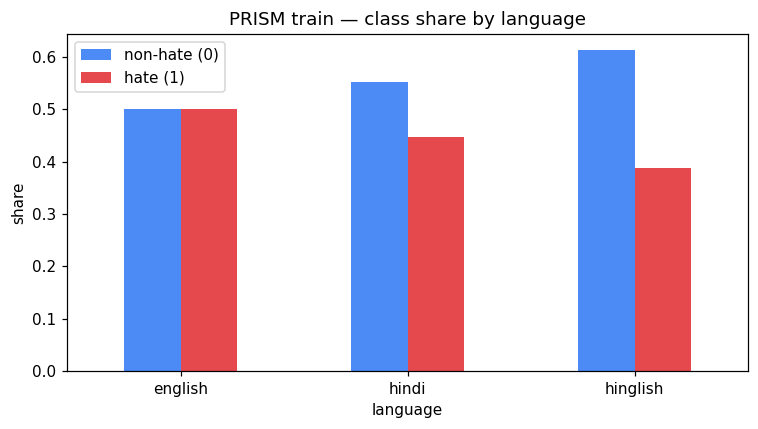

label         0      1
lang                  
english   0.500  0.500
hindi     0.552  0.448
hinglish  0.612  0.388


In [7]:
train_df = prism["train"].copy()   # copy: EDA must not mutate the shared splits

fig, ax = plt.subplots(figsize=(7, 4))
ct = pd.crosstab(train_df["lang"], train_df["label"], normalize="index")
ct.plot(kind="bar", ax=ax, rot=0, color=["#4c8bf5", "#e5484d"])
ax.set_title("PRISM train — class share by language")
ax.set_xlabel("language"); ax.set_ylabel("share")
ax.legend(["non-hate (0)", "hate (1)"])
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_class_balance.png"); plt.show()
print(ct.round(3))

### 2.2 Text-length distributions per class

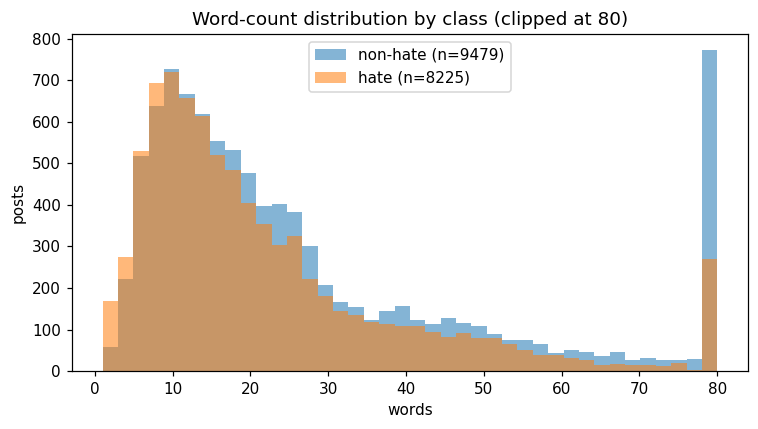

        count  mean   std  min   25%   50%   75%    max
label                                                  
0      9479.0  32.4  40.3  1.0  11.0  19.0  36.0  300.0
1      8225.0  23.7  26.2  1.0  10.0  16.0  28.0  295.0


In [8]:
train_df["n_words"] = train_df["text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(7, 4))
for lab in (0, 1):
    subset = train_df.loc[train_df["label"] == lab, "n_words"]
    ax.hist(subset.clip(upper=80), bins=40, alpha=0.55,
            label=f"{'hate' if lab else 'non-hate'} (n={len(subset)})")
ax.set_title("Word-count distribution by class (clipped at 80)")
ax.set_xlabel("words"); ax.set_ylabel("posts"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_length_dist.png"); plt.show()
print(train_df.groupby("label")["n_words"].describe().round(1))

### 2.3 Most distinctive character n-grams per class

In [9]:
from collections import Counter

def top_char_ngrams(texts, n=3, k=12):
    counts = Counter()
    for t in texts:
        norm = re.sub(r"\s+", " ", t.lower())
        counts.update(norm[i:i+n] for i in range(len(norm) - n + 1))
    return counts.most_common(k)

for lab, name in [(1, "hate"), (0, "non-hate")]:
    print(f"\nTop char trigrams — {name}:")
    print("  ", top_char_ngrams(train_df.loc[train_df["label"] == lab, "text"]))


Top char trigrams — hate:
   [(' th', 8700), ('the', 6194), ('you', 4948), (' yo', 4738), ('ing', 4398), ('he ', 4341), ('ng ', 4336), ('ou ', 3775), (' an', 3616), ('re ', 3560), (' to', 3518), ('is ', 3390)]

Top char trigrams — non-hate:
   [(' th', 18745), ('the', 13091), ('he ', 10080), (' to', 6998), ('ing', 6550), ('is ', 6420), ('ng ', 6366), ('to ', 6332), ('at ', 6265), (' an', 6006), ('ed ', 5936), ('hat', 5907)]


### 2.4 Code-mixing statistics — word-level language mixing (v2 metric)

v1 measured **script** (Devanagari ratio), which cannot see Romanised Hinglish at all.
v2 measures **language** per word: Devanagari tokens and tokens in a romanised-Hindi
lexicon count as Hindi; remaining Latin tokens count as English. Reported:

- `hindi_token_ratio` — share of Hindi-language tokens,
- `mixing_index` — minority-language token share `min(hi, en) / n` (0 = monolingual, 0.5 = balanced mix),
- `word_switch_points` — adjacent token pairs changing language (placeholders/punctuation/emoji excluded, so no phantom switches),
- `devanagari_ratio` — kept as a *script* covariate, not as the mixing measure.

*Caveat (stated in the report):* lexicon-based language ID underestimates Hindi for
content words absent from the lexicon; the index is a lower bound on mixing.

In [10]:
DEVANAGARI = re.compile(r"[\u0900-\u097F]")
TOKEN_RE   = re.compile(r"[A-Za-z\u0900-\u097F]+")
PLACEHOLDER_RE = re.compile(r"<URL>|<USER>|<EMAIL>|<PHONE>")

# Compact romanised-Hindi lexicon: function words, common adverbs and frequent
# (incl. profane) content words, with common transliteration variants.
ROMAN_HINDI = set("""
hai hain he hn nahi nahin nai nhi kya kyu kyun ku aue aur ya yaani mein me mai maiya ka ki ke ko se
par per bhi bi hi to tho toh tu tum tumhari tumhara tumhare hum humara humari apna apni apne aap
yeh ye yehe woh vo wo voh kaha kahan kab kaisa kaise kaisi itna itni jaisa jaise abhi ab kal aaj
log logon logo logo sabh sab sabhi kuch koi bahut bohut bohot bhut thoda thodi zyada jyada kam
acha achha acha achhi accha theek thik karo karna karte kar kiya kiye kardia diya diye liya liye
lena dena jata jaate jana gaya gaye gayi raha rahe rahi hogaya hogae hojayega mila mile milega
wala wali waale vale vala walla banda bande log insan insaan baat baatein baat bat kaam kaam ka
desh deshdrohi watan hindi hindustan urdu muslim hindu sikh christian pakistani bangladeshi
bharat bharatiya mullah mulla maulvi katuwa katua katwe jihadi jihad maza hab IB dat
paisa paise rupaye free bijli sadak paani school hospital naukri berojgari mehangai
gali galia gaali gaaliya galiyan maader mader behen behanchod bhosdi bhosdike bhosda chutiya
chutiye chutiye madarchod behenchod randi harami haramkhor kamina kamine kutta kutte kamina
pagal paagal bewakoof bewakoofon bakwaas bakwas bakwaas faltu ghatiya nich neech jhoota jhooth
chor chchor gaddar dhokha betray saala saale sala saley hijre hijra chakka anpadh gawar
bhookha mara maar marey marenge pitai peet pit jhagda ladai fight phir fir jab tab kabhi
kyunki kyunke liye waha yahan idhar udhar aisa waisa kaisa hoga hogi honge thi the thin
na haan han hn ji nahiin chal chalo aaja aao dekh dekho sun suno ruk jaldi abhi turant
""".split())

def _lang_of(tok: str) -> str:
    if DEVANAGARI.search(tok):
        return "hi"
    return "hi" if tok.lower() in ROMAN_HINDI else "en"

def code_mixing_stats(texts):
    rows = []
    for t in texts:
        cleaned = PLACEHOLDER_RE.sub(" ", t)
        toks = TOKEN_RE.findall(cleaned)
        n = len(toks)
        chars = re.sub(r"\s+", "", t)
        devi = len(DEVANAGARI.findall(chars)) / len(chars) if chars else 0.0
        if n == 0:
            rows.append((0.0, 0.0, 0, devi))
            continue
        langs = [_lang_of(x) for x in toks]
        hi = sum(1 for l in langs if l == "hi")
        hindi_ratio = hi / n
        minority = min(hi, n - hi) / n
        switches = sum(1 for a, b in zip(langs, langs[1:]) if a != b)
        rows.append((hindi_ratio, minority, switches, devi))
    return pd.DataFrame(rows, columns=["hindi_token_ratio", "mixing_index",
                                       "word_switch_points", "devanagari_ratio"])

mix = code_mixing_stats(train_df["text"])
train_df = pd.concat([train_df.reset_index(drop=True), mix], axis=1)
print(train_df[["hindi_token_ratio", "mixing_index", "word_switch_points", "devanagari_ratio"]]
      .describe().round(3))
print("\nMean by language:")
print(train_df.groupby("lang")[["hindi_token_ratio", "mixing_index",
                                "word_switch_points", "devanagari_ratio"]].mean().round(3))

       hindi_token_ratio  mixing_index  word_switch_points  devanagari_ratio
count          17704.000     17704.000           17704.000         17704.000
mean               0.415         0.081               3.944             0.331
std                0.428         0.124               6.848             0.471
min                0.000         0.000               0.000             0.000
25%                0.053         0.000               0.000             0.000
50%                0.167         0.000               0.000             0.000
75%                1.000         0.106               6.000             1.000
max                1.000         0.500              70.000             1.000

Mean by language:
          hindi_token_ratio  mixing_index  word_switch_points  \
lang                                                            
english               0.062         0.062               5.067   
hindi                 1.000         0.000               0.000   
hinglish              0.323 

### 2.5 Figure — mixing index and switch points by class

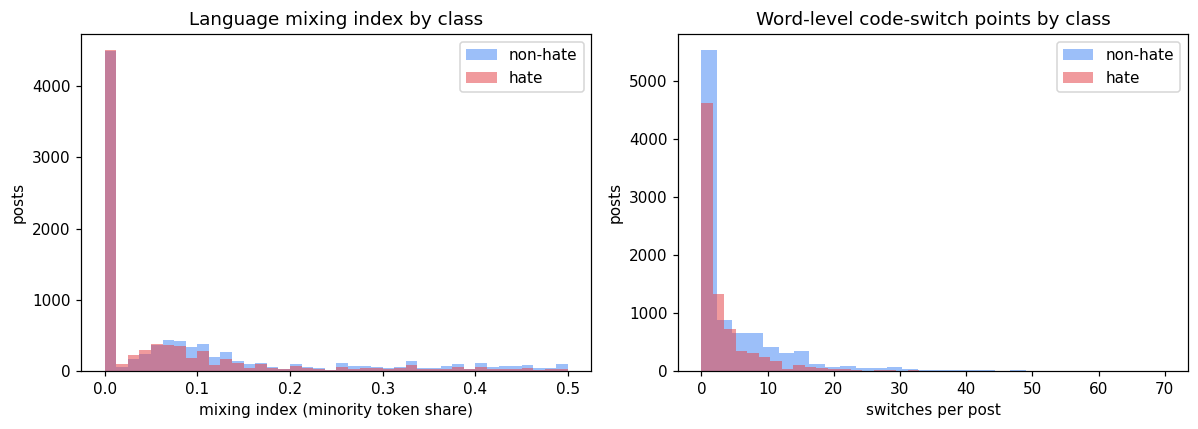

Mean mixing index by (lang, label):
label         0      1
lang                  
english   0.070  0.054
hindi     0.000  0.000
hinglish  0.325  0.279


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lab, col in [(0, "#4c8bf5"), (1, "#e5484d")]:
    axes[0].hist(train_df.loc[train_df["label"] == lab, "mixing_index"],
                 bins=40, alpha=0.55, color=col, label=f"{'hate' if lab else 'non-hate'}")
    axes[1].hist(train_df.loc[train_df["label"] == lab, "word_switch_points"],
                 bins=30, alpha=0.55, color=col, label=f"{'hate' if lab else 'non-hate'}")
axes[0].set_title("Language mixing index by class"); axes[0].set_xlabel("mixing index (minority token share)")
axes[1].set_title("Word-level code-switch points by class"); axes[1].set_xlabel("switches per post")
for ax in axes:
    ax.set_ylabel("posts"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_code_mixing.png"); plt.show()

print("Mean mixing index by (lang, label):")
print(train_df.groupby(["lang", "label"])["mixing_index"].mean().round(3).unstack())

## 3. Baseline B0 — Char n-gram TF-IDF + Linear SVM

### 3.1 Unified metric + model definition

One `compute_metrics` serves B0 and every transformer (v1 defined it twice).

In [12]:
def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"macro_f1": f, "macro_precision": p, "macro_recall": r,
            "mcc": matthews_corrcoef(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred)}

def per_class_rows(y_true, y_pred, model_label, key, seed, split):
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    rows = []
    for cls, name in (("0", "non-hate"), ("1", "hate")):
        m = rep[cls]
        rows.append({"model": model_label, "key": key, "seed": seed, "split": split,
                     "class": name, "precision": m["precision"], "recall": m["recall"],
                     "f1": m["f1-score"], "support": m["support"]})
    return rows

def record_run(model_label, key, seed, split, y_true, y_pred, extras=None):
    metrics = compute_metrics(y_true, y_pred)
    ALL_SEED_RESULTS.append({"model": model_label, "key": key, "seed": seed,
                             "split": split, **metrics, **(extras or {})})
    PER_CLASS_RESULTS.extend(per_class_rows(y_true, y_pred, model_label, key, seed, split))
    return metrics

def make_b0(seed: int) -> Pipeline:
    # Char 2-5 gram TF-IDF + LinearSVC. GPU-free, robust to romanisation noise.
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(2, 5), lowercase=True,
                                  min_df=2, max_features=300_000, sublinear_tf=True)),
        ("clf", LinearSVC(C=1.0, random_state=seed)),
    ])

X_train, y_train = prism["train"]["text"].to_numpy(), prism["train"]["label"].to_numpy()
X_val,   y_val   = prism["val"]["text"].to_numpy(),   prism["val"]["label"].to_numpy()
X_test,  y_test  = prism["test"]["text"].to_numpy(),  prism["test"]["label"].to_numpy()
print(f"train {len(X_train)} | val {len(X_val)} | test {len(X_test)}")

train 17704 | val 2950 | test 8852


### 3.2 Train and evaluate across 3 seeds (checkpointed per seed)

In [13]:
for seed in SEEDS:
    set_seed(seed)
    model = make_b0(seed)
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    train_s = time.perf_counter() - t0
    t1 = time.perf_counter()
    val_pred, test_pred = model.predict(X_val), model.predict(X_test)
    infer_ms = (time.perf_counter() - t1) / len(X_test) * 1000

    val_m  = record_run("B0 TF-IDF+SVM", "b0", seed, "val",  y_val,  val_pred)
    test_m = record_run("B0 TF-IDF+SVM", "b0", seed, "test", y_test, test_pred)
    COSTS.append({"model": "B0 TF-IDF+SVM", "key": "b0", "seed": seed,
                  "params_m": np.nan, "train_seconds": train_s, "ms_per_item": infer_ms})
    np.save(PREDS_DIR / f"b0_seed{seed}_val.npy", val_pred)
    np.save(PREDS_DIR / f"b0_seed{seed}_test.npy", test_pred)
    print(f"[b0 seed {seed}]  val macro-F1 {val_m['macro_f1']:.4f} | "
          f"test macro-F1 {test_m['macro_f1']:.4f} | train {train_s:.1f}s")

[b0 seed 42]  val macro-F1 0.7093 | test macro-F1 0.7050 | train 8.9s
[b0 seed 43]  val macro-F1 0.7093 | test macro-F1 0.7050 | train 8.9s
[b0 seed 44]  val macro-F1 0.7093 | test macro-F1 0.7050 | train 8.9s


### 3.3 Baseline summary

In [14]:
b0_test = [r for r in ALL_SEED_RESULTS if r["key"] == "b0" and r["split"] == "test"]
print(f"B0 test macro-F1 across seeds: {np.mean([r['macro_f1'] for r in b0_test]):.4f} "
      f"± {np.std([r['macro_f1'] for r in b0_test]):.4f}")

B0 test macro-F1 across seeds: 0.7050 ± 0.0000


## 4. Advanced A0 — Fine-tuned Transformers

### 4.1 Tokenised torch datasets + transformers metric adapter

In [15]:
class TextDataset(TorchDataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts, self.labels = list(texts), list(labels)
        self.tok, self.max_len = tokenizer, max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        enc = self.tok(self.texts[i], truncation=True, max_length=self.max_len,
                       padding="max_length", return_tensors="pt")
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[i], dtype=torch.long)
        return item

def compute_metrics_transformers(eval_pred):
    logits, labels = eval_pred
    return compute_metrics(labels, np.argmax(logits, axis=-1))

### 4.2 Training args (extracted — v1 buried this in a 72-line method)

In [16]:
def build_training_args(model_key: str, seed: int) -> TrainingArguments:
    # Smoke mode: max_steps (4) < one epoch, so eval/save must be step-based for
    # load_best_model_at_end to have a checkpoint to restore.
    if SMOKE_TEST:
        schedule = dict(eval_strategy="steps", eval_steps=2,
                        save_strategy="steps", save_steps=2, max_steps=4)
    else:
        schedule = dict(eval_strategy="epoch", save_strategy="epoch")
    return TrainingArguments(
        output_dir=str(WORK_DIR / f"ckpt_{model_key}_seed{seed}"),
        seed=seed, data_seed=seed,
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE * 2,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1", greater_is_better=True,
        learning_rate=LR, weight_decay=WEIGHT_DECAY, warmup_ratio=WARMUP_RATIO,
        fp16=(DEVICE.type == "cuda" and not SMOKE_TEST),
        logging_steps=50, save_total_limit=1, report_to="none",
        **schedule,
    )

### 4.3 Prediction, threshold tuning (on **validation** only) and checkpointing

In [17]:
def tune_threshold(y_val_true, val_probs):
    ths = np.arange(0.05, 0.96, 0.01)
    f1s = np.array([f1_score(y_val_true, (val_probs >= t).astype(int),
                             average="macro", zero_division=0) for t in ths])
    return float(ths[int(np.argmax(f1s))]), ths, f1s

def predict_and_checkpoint(trainer, tok, model_key, seed):
    t0 = time.perf_counter()
    val_out  = trainer.predict(TextDataset(X_val,  y_val,  tok, MAX_LEN))
    test_out = trainer.predict(TextDataset(X_test, y_test, tok, MAX_LEN))
    infer_ms = (time.perf_counter() - t0) / len(X_test) * 1000

    val_probs  = torch.softmax(torch.tensor(val_out.predictions),  dim=-1)[:, 1].numpy()
    test_probs = torch.softmax(torch.tensor(test_out.predictions), dim=-1)[:, 1].numpy()

    thr, ths, curve = tune_threshold(y_val, val_probs)      # tuned on VALIDATION only
    val_pred  = (val_probs  >= thr).astype(int)
    test_pred = (test_probs >= thr).astype(int)
    test_argmax = np.argmax(test_out.predictions, axis=-1)  # fixed-0.5 comparison

    np.save(PREDS_DIR / f"{model_key}_seed{seed}_val.npy", val_pred)
    np.save(PREDS_DIR / f"{model_key}_seed{seed}_test.npy", test_pred)
    np.save(PREDS_DIR / f"{model_key}_seed{seed}_test_probs.npy", test_probs)
    np.save(PREDS_DIR / f"{model_key}_seed{seed}_thr.npy", np.array([thr]))
    return val_pred, test_pred, test_probs, test_argmax, thr, ths, curve, infer_ms

### 4.4 One harness, three backbones (memory-safe: only seed-42 model stays resident)

In [18]:
def run_transformer(model_key: str, model_name: str, seed: int):
    set_seed(seed)
    hf_set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6

    trainer = Trainer(model=model, args=build_training_args(model_key, seed),
                      train_dataset=TextDataset(X_train, y_train, tok, MAX_LEN),
                      eval_dataset=TextDataset(X_val, y_val, tok, MAX_LEN),
                      processing_class=tok, compute_metrics=compute_metrics_transformers)
    t0 = time.perf_counter()
    trainer.train()
    train_s = time.perf_counter() - t0
    LOG_HISTORY[(model_key, seed)] = trainer.state.log_history

    val_pred, test_pred, test_probs, test_argmax, thr, ths, curve, infer_ms = \
        predict_and_checkpoint(trainer, tok, model_key, seed)
    THRESH_CURVES[(model_key, seed)] = (ths, curve)

    extras = {"threshold": thr, "test_macro_f1_argmax":
              compute_metrics(y_test, test_argmax)["macro_f1"]}
    val_m  = record_run(model_key, model_key, seed, "val",  y_val,  val_pred,  extras)
    test_m = record_run(model_key, model_key, seed, "test", y_test, test_pred, extras)
    COSTS.append({"model": model_key, "key": model_key, "seed": seed,
                  "params_m": n_params, "train_seconds": train_s, "ms_per_item": infer_ms})

    if seed == SEEDS[0]:
        # Only the seed-42 artefacts are reused later (sections 6-7): keep resident.
        TRAINED[(model_key, seed)] = {"tokenizer": tok, "model": trainer.model,
                                      "val_pred": val_pred, "test_pred": test_pred,
                                      "test_probs": test_probs, "threshold": thr}
    else:
        del trainer, model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    shutil.rmtree(WORK_DIR / f"ckpt_{model_key}_seed{seed}", ignore_errors=True)
    print(f"[{model_key} seed {seed}]  val macro-F1 {val_m['macro_f1']:.4f} | "
          f"test macro-F1 {test_m['macro_f1']:.4f} @ thr={thr:.2f} | "
          f"train {train_s:.0f}s | {infer_ms:.2f} ms/item")

### 4.5 A0 headline — HingRoBERTa (pretrained on ~1B tokens of romanised Hinglish)

In [19]:
for seed in SEEDS:
    run_transformer("hing-roberta", MODELS["hing-roberta"], seed)

tokenizer_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/750 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (5 outputs left out)

[hing-roberta seed 43]  val macro-F1 0.7382 | test macro-F1 0.7255 @ thr=0.46 | train 856s | 6.56 ms/item


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at l3cube-pune/hing-roberta and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Macro Precision,Macro Recall,Mcc,Balanced Accuracy
1,0.538100,0.532816,0.704491,0.729279,0.705634,0.434270,0.705634
2,0.471900,0.527509,0.729342,0.742423,0.728573,0.470793,0.728573
3,0.420700,0.533077,0.741303,0.753272,0.740229,0.493329,0.740229


[hing-roberta seed 44]  val macro-F1 0.7413 | test macro-F1 0.7281 @ thr=0.50 | train 856s | 6.57 ms/item


### 4.6 Control 1 — MuRIL (Indian-language pretraining, Devanagari-strong)

In [20]:
for seed in SEEDS:
    run_transformer("muril", MODELS["muril"], seed)

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/953M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/953M [00:00<?, ?B/s]

... (5 outputs left out)

[muril seed 43]  val macro-F1 0.7415 | test macro-F1 0.7292 @ thr=0.51 | train 823s | 6.88 ms/item


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/muril-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Macro Precision,Macro Recall,Mcc,Balanced Accuracy
1,0.638400,0.614769,0.668633,0.711514,0.674665,0.384417,0.674665
2,0.571400,0.561155,0.714297,0.723295,0.713603,0.436790,0.713603
3,0.539300,0.543490,0.727720,0.737333,0.726818,0.464032,0.726818


[muril seed 44]  val macro-F1 0.7298 | test macro-F1 0.7263 @ thr=0.52 | train 823s | 6.88 ms/item


### 4.7 Control 2 — XLM-RoBERTa (multilingual generalist)

In [21]:
for seed in SEEDS:
    run_transformer("xlm-roberta", MODELS["xlm-roberta"], seed)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (4 outputs left out)

[xlm-roberta seed 43]  val macro-F1 0.7449 | test macro-F1 0.7268 @ thr=0.51 | train 857s | 6.59 ms/item


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Macro Precision,Macro Recall,Mcc,Balanced Accuracy
1,0.587300,0.570854,0.697396,0.731996,0.700164,0.430986,0.700164
2,0.511900,0.504563,0.744937,0.755382,0.743756,0.499003,0.743756
3,0.459300,0.524634,0.743170,0.758274,0.742179,0.500194,0.742179


[xlm-roberta seed 44]  val macro-F1 0.7479 | test macro-F1 0.7363 @ thr=0.48 | train 857s | 6.60 ms/item


## 5. Evaluation & Statistical Testing

### 5.1 Per-seed results → `results.csv`

In [22]:
results_df = pd.DataFrame(ALL_SEED_RESULTS)
results_df.to_csv(RESULTS_DIR / "results.csv", index=False)
pd.DataFrame(PER_CLASS_RESULTS).to_csv(RESULTS_DIR / "per_class.csv", index=False)
results_df

,model,key,seed,split,macro_f1,macro_precision,macro_recall,mcc,balanced_accuracy,threshold,test_macro_f1_argmax
0,B0 TF-IDF+SVM,b0,42,val,0.709319,0.710089,0.708916,0.419003,0.708916,NaN,NaN
1,B0 TF-IDF+SVM,b0,42,test,0.705045,0.705691,0.704689,0.410379,0.704689,NaN,NaN
2,B0 TF-IDF+SVM,b0,43,val,0.709319,0.710089,0.708916,0.419003,0.708916,NaN,NaN
3,B0 TF-IDF+SVM,b0,43,test,0.705045,0.705691,0.704689,0.410379,0.704689,NaN,NaN
4,B0 TF-IDF+SVM,b0,44,val,0.709319,0.710089,0.708916,0.419003,0.708916,NaN,NaN
5,B0 TF-IDF+SVM,b0,44,test,0.705045,0.705691,0.704689,0.410379,0.704689,NaN,NaN
6,hing-roberta,hing-roberta,42,val,0.747424,0.750806,0.746424,0.497211,0.746424,0.47,0.734055
7,hing-roberta,hing-roberta,42,test,0.736288,0.738795,0.735459,0.474243,0.735459,0.47,0.734055
8,hing-roberta,hing-roberta,43,val,0.738237,0.740594,0.737418,0.478002,0.737418,0.46,0.714205
9,hing-roberta,hing-roberta,43,test,0.725473,0.726421,0.724990,0.451409,0.724990,0.46,0.714205


### 5.2 Mean summary + bootstrap CI **around the 3-seed mean**

v1 plotted a seed-42 CI around a 3-seed mean. v2 resamples the test set and averages
macro-F1 across seeds *within* each resample, so the interval surrounds the plotted mean.

In [23]:
def bootstrap_ci_mean(y_true, preds_list, n_boot=BOOTSTRAP_N, seed=0):
    rng = np.random.default_rng(seed)
    idx = np.arange(len(y_true))
    P = np.stack(preds_list)
    scores = np.empty(n_boot)
    for b_i in range(n_boot):
        b = rng.choice(idx, size=len(idx), replace=True)
        scores[b_i] = np.mean([f1_score(y_true[b], P[j][b], average="macro", zero_division=0)
                               for j in range(P.shape[0])])
    return np.percentile(scores, [2.5, 97.5])

summary_rows = []
for key, label in [("b0", "B0 TF-IDF+SVM"), ("hing-roberta", "A0 HingRoBERTa"),
                   ("muril", "A0 MuRIL"), ("xlm-roberta", "A0 XLM-R")]:
    test_rows = [r for r in ALL_SEED_RESULTS if r["key"] == key and r["split"] == "test"]
    if not test_rows:
        continue
    try:
        preds = [np.load(PREDS_DIR / f"{key}_seed{s}_test.npy") for s in SEEDS]
        lo, hi = bootstrap_ci_mean(y_test, preds)
    except FileNotFoundError:
        lo = hi = np.nan
    summary_rows.append({
        "model": label, "key": key,
        "macro_f1_mean": np.mean([r["macro_f1"] for r in test_rows]),
        "macro_f1_std":  np.std([r["macro_f1"] for r in test_rows]),
        "mcc_mean":  np.mean([r["mcc"] for r in test_rows]),
        "balanced_acc_mean": np.mean([r["balanced_accuracy"] for r in test_rows]),
        "threshold_mean": np.nanmean([r.get("threshold", np.nan) for r in test_rows]),
        "ci_low": lo, "ci_high": hi,
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
summary.round(4)

,model,key,macro_f1_mean,macro_f1_std,mcc_mean,balanced_acc_mean,threshold_mean,ci_low,ci_high
0,B0 TF-IDF+SVM,b0,0.7050,0.0000,0.4104,0.7047,NaN,0.6957,0.7144
1,A0 HingRoBERTa,hing-roberta,0.7300,0.0046,0.4639,0.7292,0.4767,0.7214,0.7386
2,A0 MuRIL,muril,0.7254,0.0036,0.4582,0.7245,0.5133,0.7168,0.7343
3,A0 XLM-R,xlm-roberta,0.7351,0.0064,0.4794,0.7344,0.5067,0.7265,0.7439


### 5.3 McNemar (seed 42) + Holm-corrected significance across 3 comparisons

In [24]:
def mcnemar(y_true, pred_a, pred_b):
    # Exact binomial McNemar on discordant pairs.
    a_correct, b_correct = pred_a == y_true, pred_b == y_true
    n01 = int(np.sum(a_correct & ~b_correct))   # A right, B wrong
    n10 = int(np.sum(~a_correct & b_correct))   # A wrong, B right
    if n01 + n10 == 0:
        return 1.0, n01, n10
    return stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue, n01, n10

b0_ref = np.load(PREDS_DIR / f"b0_seed{SEEDS[0]}_test.npy")
stat_rows = []
for key, label in [("hing-roberta", "A0 HingRoBERTa"), ("muril", "A0 MuRIL"),
                   ("xlm-roberta", "A0 XLM-R")]:
    try:
        a_pred = np.load(PREDS_DIR / f"{key}_seed{SEEDS[0]}_test.npy")
    except FileNotFoundError:
        continue
    p, n01, n10 = mcnemar(y_test, a_pred, b0_ref)
    stat_rows.append({"model": label, "p_value": p, "A_right_B_wrong": n01,
                      "A_wrong_B_right": n10, "p_holm_adj": min(1.0, p * len(SEEDS)),
                      "significant_at_0.05_holm": min(1.0, p * 3) < 0.05})
stats_df = pd.DataFrame(stat_rows)
stats_df.to_csv(RESULTS_DIR / "mcnemar.csv", index=False)
stats_df

,model,p_value,A_right_B_wrong,A_wrong_B_right,p_holm_adj,significant_at_0.05_holm
0,A0 HingRoBERTa,2.491427e-09,1263,980,7.474281e-09,True
1,A0 MuRIL,1.042699e-04,1094,919,3.128096e-04,True
2,A0 XLM-R,4.142310e-14,1181,841,1.242693e-13,True


### 5.4 Figure 1 — Macro-F1: 3-seed mean with bootstrap CI of the mean

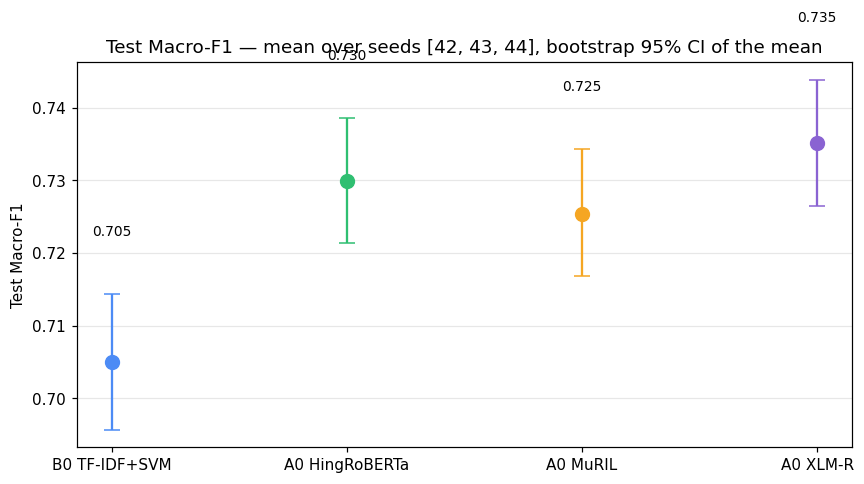

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"b0": "#4c8bf5", "hing-roberta": "#2fbf71", "muril": "#f5a623", "xlm-roberta": "#8a63d2"}
for _, row in summary.iterrows():
    ax.errorbar(row["model"], row["macro_f1_mean"],
                yerr=[[max(0.0, row["macro_f1_mean"] - row["ci_low"])],
                      [max(0.0, row["ci_high"] - row["macro_f1_mean"])]],
                fmt="o", capsize=5, color=colors.get(row["key"], "gray"), markersize=9)
    ax.text(row["model"], row["ci_high"] + 0.008, f"{row['macro_f1_mean']:.3f}", ha="center", fontsize=9)
ax.set_ylabel("Test Macro-F1")
ax.set_title(f"Test Macro-F1 — mean over seeds {SEEDS}, bootstrap 95% CI of the mean")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig1_macro_f1_ci.png"); plt.show()

### 5.5 Figure — per-class precision / recall / F1 (the brief's missing view)

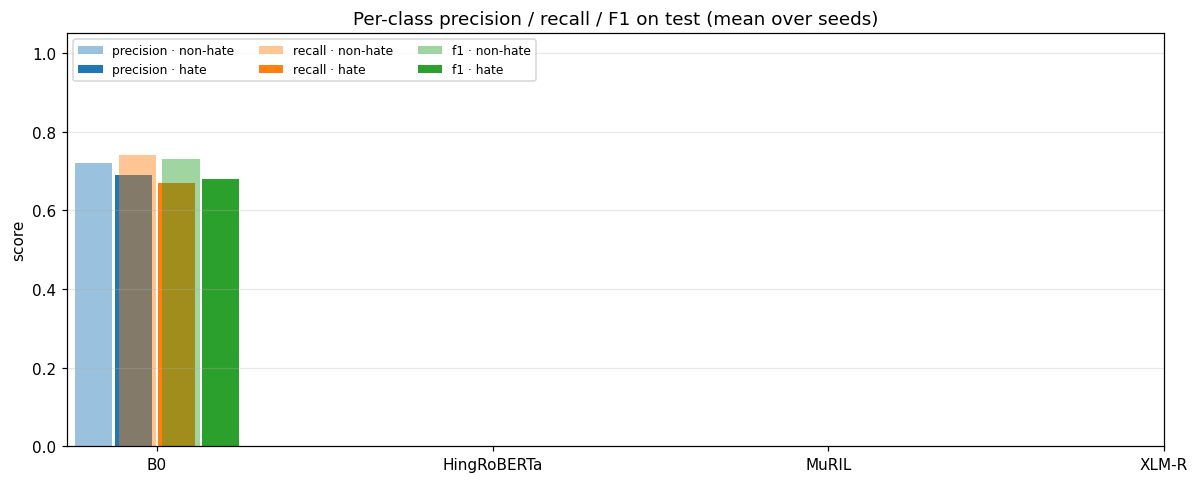

,model,class,precision,recall,f1
0,B0 TF-IDF+SVM,hate,0.691,0.670,0.680
1,B0 TF-IDF+SVM,non-hate,0.721,0.740,0.730
2,NaN,hate,0.736,0.667,0.699
4,NaN,hate,0.747,0.636,0.687
6,NaN,hate,0.762,0.645,0.697
3,NaN,non-hate,0.733,0.792,0.761
5,NaN,non-hate,0.720,0.813,0.764
7,NaN,non-hate,0.729,0.824,0.773


In [26]:
per_class_df = pd.DataFrame(PER_CLASS_RESULTS)
pc_test = per_class_df[per_class_df["split"] == "test"].groupby(["model", "class"])[["precision", "recall", "f1"]].mean().reset_index()
order = ["B0 TF-IDF+SVM", "A0 HingRoBERTa", "A0 MuRIL", "A0 XLM-R"]
pc_test["model"] = pd.Categorical(pc_test["model"], order, ordered=True)
pc_test = pc_test.sort_values(["model", "class"])

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(order))
w = 0.13
for i, metric in enumerate(["precision", "recall", "f1"]):
    for j, cls in enumerate(["non-hate", "hate"]):
        vals = [pc_test[(pc_test["model"] == m) & (pc_test["class"] == cls)][metric].mean() for m in order]
        ax.bar(x + (i - 1) * w + (j - 0.5) * w * 0.9, vals, width=w * 0.85,
               label=f"{metric} · {cls}",
               color=plt.cm.tab10(i), alpha=0.45 + 0.55 * j)
ax.set_xticks(x, ["B0", "HingRoBERTa", "MuRIL", "XLM-R"])
ax.set_ylim(0, 1.05); ax.set_ylabel("score")
ax.set_title("Per-class precision / recall / F1 on test (mean over seeds)")
ax.legend(ncol=3, fontsize=8); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_per_class.png"); plt.show()
pc_test.round(3)

### 5.6 Figure — cost vs quality (parameters, training time, ms/inference)

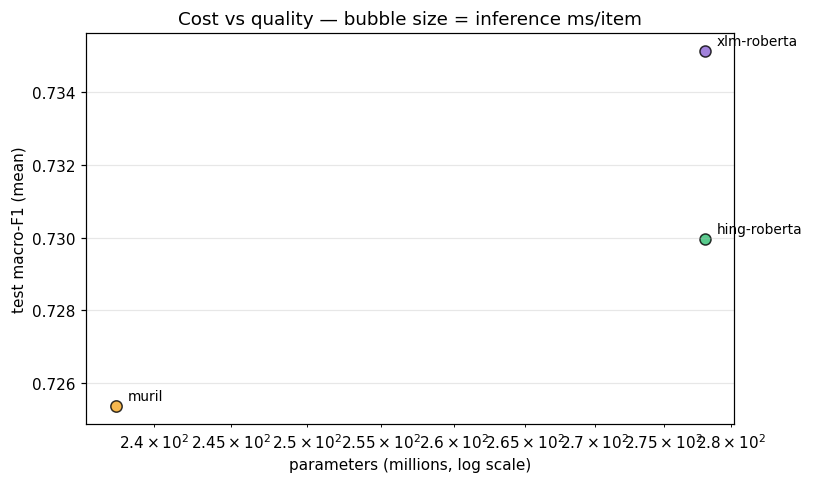

,key,params_m,train_seconds,ms_per_item,macro_f1_mean
0,b0,NaN,8.929,0.499,0.705
1,hing-roberta,278.045,856.285,6.563,0.730
2,muril,237.558,823.395,6.878,0.725
3,xlm-roberta,278.045,857.433,6.596,0.735


In [27]:
costs_df = pd.DataFrame(COSTS)
costs_df.to_csv(RESULTS_DIR / "costs.csv", index=False)
cost_agg = costs_df.groupby("key").agg(params_m=("params_m", "mean"),
                                       train_seconds=("train_seconds", "mean"),
                                       ms_per_item=("ms_per_item", "mean")).reset_index()
cost_agg = cost_agg.merge(summary[["key", "macro_f1_mean"]], on="key")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for _, r in cost_agg.iterrows():
    ax.scatter(r["params_m"], r["macro_f1_mean"], s=max(40, r["ms_per_item"] * 8),
               color=colors.get(r["key"], "gray"), alpha=0.8, edgecolor="k")
    ax.annotate(r["key"], (r["params_m"], r["macro_f1_mean"]),
                textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("parameters (millions, log scale)"); ax.set_ylabel("test macro-F1 (mean)")
ax.set_title("Cost vs quality — bubble size = inference ms/item")
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_cost_f1.png"); plt.show()
cost_agg.round(3)

### 5.7 Figure — validation threshold sweep (why 0.5 was not blindly used)

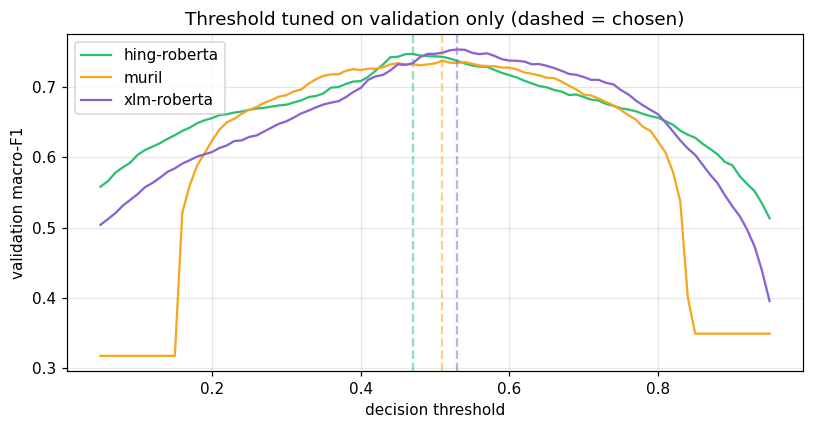

hing-roberta tuned thr=0.47  tuned-F1=0.7363  argmax-F1=0.7341
muril        tuned thr=0.51  tuned-F1=0.7206  argmax-F1=0.7211
xlm-roberta  tuned thr=0.53  tuned-F1=0.7424  argmax-F1=0.7408


In [28]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for key in ("hing-roberta", "muril", "xlm-roberta"):
    if (key, SEEDS[0]) in THRESH_CURVES:
        ths, curve = THRESH_CURVES[(key, SEEDS[0])]
        ax.plot(ths, curve, label=key, color=colors.get(key))
        thr_used = [r["threshold"] for r in ALL_SEED_RESULTS
                    if r["key"] == key and r["seed"] == SEEDS[0] and r["split"] == "test"][0]
        ax.axvline(thr_used, color=colors.get(key), ls="--", alpha=0.5)
ax.set_xlabel("decision threshold"); ax.set_ylabel("validation macro-F1")
ax.set_title("Threshold tuned on validation only (dashed = chosen)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_threshold.png"); plt.show()

for key in ("hing-roberta", "muril", "xlm-roberta"):
    rows = [r for r in ALL_SEED_RESULTS if r["key"] == key and r["split"] == "test" and r["seed"] == SEEDS[0]]
    if rows:
        print(f"{key:12s} tuned thr={rows[0]['threshold']:.2f}  "
              f"tuned-F1={rows[0]['macro_f1']:.4f}  argmax-F1={rows[0]['test_macro_f1_argmax']:.4f}")

### 5.8 Figure — learning curves (HingRoBERTa, seed 42)

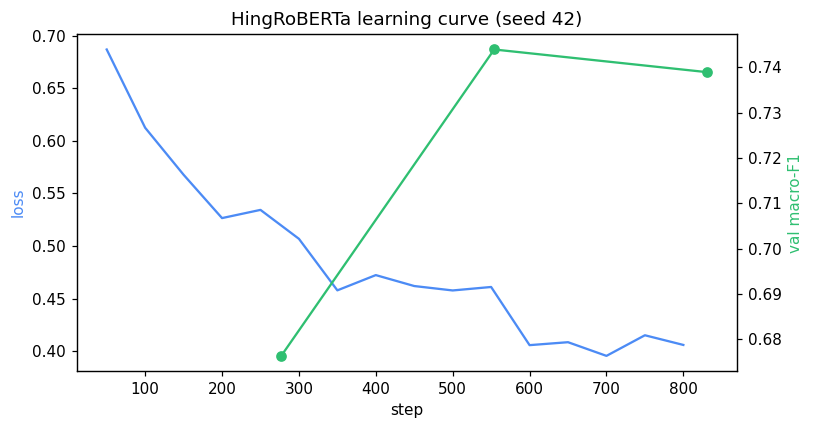

In [29]:
hist = LOG_HISTORY.get(("hing-roberta", SEEDS[0]), [])
if hist:
    steps  = [h["step"] for h in hist if "loss" in h]
    losses = [h["loss"] for h in hist if "loss" in h]
    ev_steps  = [h["step"] for h in hist if "eval_macro_f1" in h]
    ev_f1     = [h["eval_macro_f1"] for h in hist if "eval_macro_f1" in h]
    fig, ax1 = plt.subplots(figsize=(7.5, 4))
    ax1.plot(steps, losses, color="#4c8bf5", label="train loss")
    ax1.set_xlabel("step"); ax1.set_ylabel("loss", color="#4c8bf5")
    ax2 = ax1.twinx()
    ax2.plot(ev_steps, ev_f1, color="#2fbf71", marker="o", label="val macro-F1")
    ax2.set_ylabel("val macro-F1", color="#2fbf71")
    ax1.set_title(f"HingRoBERTa learning curve (seed {SEEDS[0]})")
    fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_learning_curve.png"); plt.show()
else:
    print("No log history (smoke mode?) — skipped.")

## 6. Error Analysis of Code-Mixing Challenges

### 6.1 Best A0 selected on **validation** + confusion matrices

Val mean macro-F1: {'hing-roberta': np.float64(0.7423), 'muril': np.float64(0.7363), 'xlm-roberta': np.float64(0.7488)}
Best A0 backbone (chosen on VALIDATION): xlm-roberta


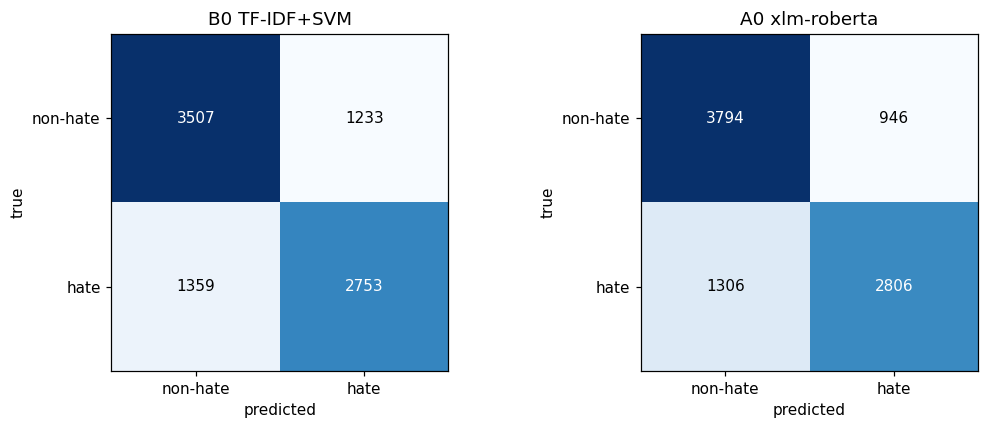

In [30]:
# v1 selected the backbone on TEST macro-F1. v2 selects on validation; test is reported only.
val_means = {k: np.mean([r["macro_f1"] for r in ALL_SEED_RESULTS
                         if r["key"] == k and r["split"] == "val"])
             for k in ("hing-roberta", "muril", "xlm-roberta")
             if any(r["key"] == k and r["split"] == "val" for r in ALL_SEED_RESULTS)}
best_a0 = max(val_means, key=val_means.get)
print("Val mean macro-F1:", {k: round(v, 4) for k, v in val_means.items()})
print("Best A0 backbone (chosen on VALIDATION):", best_a0)

a0_pred = np.load(PREDS_DIR / f"{best_a0}_seed{SEEDS[0]}_test.npy")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("B0 TF-IDF+SVM", b0_ref), (f"A0 {best_a0}", a0_pred)]):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["non-hate", "hate"]); ax.set_yticks([0, 1], ["non-hate", "hate"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(name)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_confusion.png"); plt.show()

### 6.2 Performance per language — where does code-mixing hurt?

In [31]:
test_df = prism["test"].copy()
test_df["b0_pred"] = b0_ref
test_df["a0_pred"] = a0_pred

per_lang = []
for lang, grp in test_df.groupby("lang"):
    per_lang.append({"lang": lang, "n": len(grp),
                     "b0_macro_f1": f1_score(grp["label"], grp["b0_pred"], average="macro", zero_division=0),
                     "a0_macro_f1": f1_score(grp["label"], grp["a0_pred"], average="macro", zero_division=0)})
per_lang = pd.DataFrame(per_lang)
per_lang.to_csv(RESULTS_DIR / "per_language.csv", index=False)
per_lang.round(4)

,lang,n,b0_macro_f1,a0_macro_f1
0,english,4545,0.7723,0.8189
1,hindi,2900,0.6215,0.6233
2,hinglish,1407,0.6312,0.6680


### 6.3 Misclassifications by **language-mixing** bucket (v2 metric)

Buckets on `mixing_index` (minority-token share), so Romanised Hinglish is finally visible.

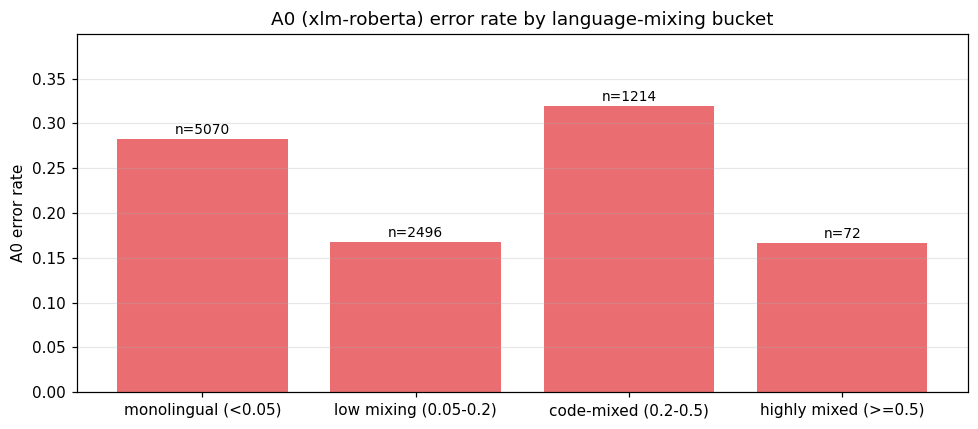

,phenomenon,n,a0_error_rate,a0_macro_f1,mean_word_switches
0,monolingual (<0.05),5070,0.2826,0.7170,0.3848
1,low mixing (0.05-0.2),2496,0.1679,0.8298,8.2412
2,code-mixed (0.2-0.5),1214,0.3196,0.6274,9.4852
3,highly mixed (>=0.5),72,0.1667,0.7000,7.9444


In [32]:
test_mix = code_mixing_stats(test_df["text"])
test_df["mixing_index"] = test_mix["mixing_index"].to_numpy()
test_df["word_switch_points"] = test_mix["word_switch_points"].to_numpy()
test_df["devanagari_ratio"] = test_mix["devanagari_ratio"].to_numpy()
test_df["a0_wrong"] = test_df["a0_pred"] != test_df["label"]

buckets = {
    "monolingual (<0.05)":   test_df["mixing_index"] < 0.05,
    "low mixing (0.05-0.2)": (test_df["mixing_index"] >= 0.05) & (test_df["mixing_index"] < 0.2),
    "code-mixed (0.2-0.5)":  (test_df["mixing_index"] >= 0.2) & (test_df["mixing_index"] < 0.5),
    "highly mixed (>=0.5)":  test_df["mixing_index"] >= 0.5,
}
phen_rows = []
for name, mask in buckets.items():
    sub = test_df[mask]
    if len(sub) == 0:
        continue
    phen_rows.append({"phenomenon": name, "n": len(sub),
                      "a0_error_rate": sub["a0_wrong"].mean(),
                      "a0_macro_f1": f1_score(sub["label"], sub["a0_pred"], average="macro", zero_division=0),
                      "mean_word_switches": sub["word_switch_points"].mean()})
phenomena = pd.DataFrame(phen_rows)
phenomena.to_csv(RESULTS_DIR / "error_phenomena.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(phenomena["phenomenon"], phenomena["a0_error_rate"], color="#e5484d", alpha=0.8)
for i, (n, e) in enumerate(zip(phenomena["n"], phenomena["a0_error_rate"])):
    ax.text(i, e + 0.005, f"n={n}", ha="center", fontsize=9)
ax.set_ylabel("A0 error rate"); ax.set_ylim(0, max(phenomena["a0_error_rate"]) * 1.25)
ax.set_title(f"A0 ({best_a0}) error rate by language-mixing bucket")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_error_phenomena.png"); plt.show()
phenomena.round(4)

### 6.4 Qualitative export — disagreeing examples for the report

In [33]:
disagree = test_df.loc[test_df["b0_pred"] != test_df["a0_pred"],
                       ["text", "label", "lang", "b0_pred", "a0_pred", "mixing_index", "word_switch_points"]]
disagree = disagree.rename(columns={"label": "true", "b0_pred": "b0", "a0_pred": f"a0_{best_a0}",
                                    "word_switch_points": "code_switch_points"})
disagree.to_csv(RESULTS_DIR / "qualitative_disagreements.csv", index=False)
print(f"Exported {len(disagree)} B0-vs-A0 disagreement examples.")
disagree.head(10)

Exported 2022 B0-vs-A0 disagreement examples.


,text,true,lang,b0,a0_xlm-roberta,mixing_index,code_switch_points
1,why are you making me jump through hoops when ...,0,english,1,0,0.076923,8
2,give this up here is something you should take...,1,english,1,0,0.073171,10
3,are your friends safe living with a crush on y...,1,english,1,0,0.000000,0
5,and you know he is probably saying the softest...,1,english,0,1,0.117647,8
7,laughing my ass off you guys i remember when s...,0,english,1,0,0.076923,4
9,मैं एक दलित की जान बचाने के लिए कभी उंगली नहीं...,1,hindi,0,1,0.000000,0
12,जिस प्रदेश का मुख्यमंत्री ही सुरक्षित नहीं है ...,1,hindi,1,0,0.000000,0
17,times like all its kind,1,english,1,0,0.000000,0
19,यह स्पष्ट है कि निचली जात के लोग मूरखता के बिल...,0,hindi,0,1,0.000000,0
21,almost frantic as we,1,english,0,1,0.000000,0


## 7. Cross-Lingual Transfer — Marathi-English (MeHate)

### 7.1 Load MeHate at a pinned commit (zero-shot only — no training, no leakage)

*Disclosure:* this uses the **small** code-mixed test split (n≈416), not the full ~2.7K
corpus; the sentiment/profanity columns are not used. Both facts are stated in the report.

In [34]:
def github_head_sha(repo: str) -> str:
    with urllib.request.urlopen(f"https://api.github.com/repos/{repo}/commits/main", timeout=30) as r:
        return json.load(r)["sha"]

MEHATE_SHA = github_head_sha(MEHATE_REPO)
MEHATE_URL = f"https://raw.githubusercontent.com/{MEHATE_REPO}/{MEHATE_SHA}/{MEHATE_CSV}"
print(f"MeHate revision (pinned): {MEHATE_SHA}")

mehate_test = pd.read_csv(MEHATE_URL)
mehate_test = mehate_test.rename(columns={"tweet": "text", "hate": "label"})
mehate_test = mehate_test[["text", "label"]].copy()
mehate_test["text"] = mehate_test["text"].astype(str).map(deidentify)
mehate_test["label"] = mehate_test["label"].astype(float).astype(int)
assert set(mehate_test["label"].unique()) <= {0, 1}, "unexpected MeHate labels"
if SMOKE_TEST:
    mehate_test = mehate_test.head(100).reset_index(drop=True)
print(f"MeHate test: {len(mehate_test)} rows | balance "
      f"{mehate_test['label'].value_counts(normalize=True).round(3).to_dict()}")

MeHate revision (pinned): 8ee29fa1329d6a841030eb46659d3c10614b5e59
MeHate test: 416 rows | balance {0: 0.5, 1: 0.5}


### 7.2 Zero-shot transfer with the validation-selected A0 model (seed 42) + bootstrap CI

In [35]:
best_trained = TRAINED[(best_a0, SEEDS[0])]
tok_best, model_best = best_trained["tokenizer"], best_trained["model"]

mehate_ds = TextDataset(mehate_test["text"], mehate_test["label"], tok_best, MAX_LEN)
transfer_trainer = Trainer(model=model_best, args=TrainingArguments(
    output_dir=str(WORK_DIR / "ckpt_transfer"),
    per_device_eval_batch_size=BATCH_SIZE * 2, report_to="none"), processing_class=tok_best)
transfer_logits = transfer_trainer.predict(mehate_ds).predictions
mehate_probs = torch.softmax(torch.tensor(transfer_logits), dim=-1)[:, 1].numpy()
mehate_pred = (mehate_probs >= best_trained["threshold"]).astype(int)   # same val-tuned threshold

y_mh = mehate_test["label"].to_numpy()
transfer_f1 = f1_score(y_mh, mehate_pred, average="macro", zero_division=0)
rng = np.random.default_rng(0)
mh_idx = np.arange(len(y_mh))
mh_scores = [f1_score(y_mh[b], mehate_pred[b], average="macro", zero_division=0)
             for b in (rng.choice(mh_idx, len(mh_idx), replace=True) for _ in range(200))]
mh_lo, mh_hi = np.percentile(mh_scores, [2.5, 97.5])
np.save(PREDS_DIR / f"{best_a0}_mehate_seed{SEEDS[0]}.npy", mehate_pred)
print(f"MeHate zero-shot macro-F1 = {transfer_f1:.4f} (95% CI {mh_lo:.4f}–{mh_hi:.4f}, "
      f"n={len(y_mh)}, threshold {best_trained['threshold']:.2f} carried from PRISM-val)")

MeHate zero-shot macro-F1 = 0.3770 (95% CI 0.3454–0.4088, n=416, threshold 0.53 carried from PRISM-val)


### 7.3 Transfer table + figure — PRISM (Hindi-English) → MeHate (Marathi-English)

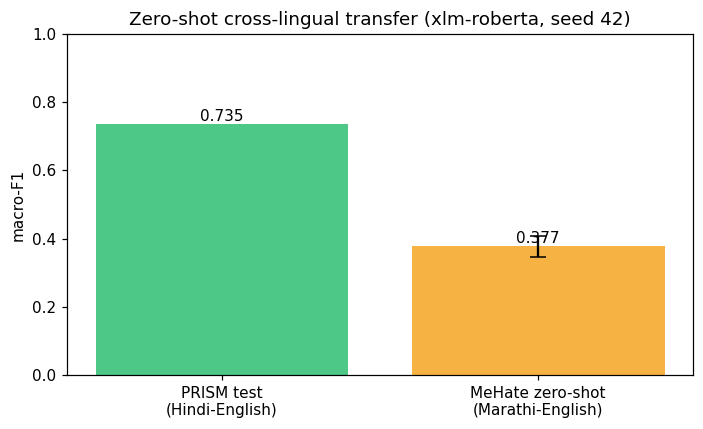

,model,PRISM test Macro-F1 (Hindi-English),MeHate zero-shot Macro-F1 (Marathi-English),MeHate CI low,MeHate CI high,MeHate n,drop
0,A0 xlm-roberta (trained on PRISM),0.7351,0.377,0.3454,0.4088,416,0.3581


In [36]:
prism_f1 = float(summary.loc[summary["key"] == best_a0, "macro_f1_mean"].iloc[0])
transfer = pd.DataFrame([{
    "model": f"A0 {best_a0} (trained on PRISM)",
    "PRISM test Macro-F1 (Hindi-English)": prism_f1,
    "MeHate zero-shot Macro-F1 (Marathi-English)": transfer_f1,
    "MeHate CI low": mh_lo, "MeHate CI high": mh_hi,
    "MeHate n": len(y_mh),
    "drop": prism_f1 - transfer_f1,
}])
transfer.to_csv(RESULTS_DIR / "transfer.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4))
vals = [prism_f1, transfer_f1]
ax.bar(["PRISM test\n(Hindi-English)", "MeHate zero-shot\n(Marathi-English)"], vals,
       color=["#2fbf71", "#f5a623"], alpha=0.85)
ax.errorbar(1, transfer_f1, yerr=[[transfer_f1 - mh_lo], [mh_hi - transfer_f1]],
            fmt="none", ecolor="k", capsize=5)
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
ax.set_ylim(0, 1); ax.set_ylabel("macro-F1")
ax.set_title(f"Zero-shot cross-lingual transfer ({best_a0}, seed {SEEDS[0]})")
fig.tight_layout(); fig.savefig(FIGURES_DIR / "fig_transfer.png"); plt.show()
transfer.round(4)

## 8. Self-tests — helpers verified before trusting the results

Fast assertions on the deterministic helpers (mirrors the external pressure test).
If any of these fail, do not trust the sections above.

In [37]:
checks = []
def expect(name, cond):
    checks.append((name, bool(cond)))
    print(("  PASS  " if cond else "  FAIL  ") + name)

# de-identification
expect("handle -> <USER>", deidentify("hi @rahul!") == "hi <USER>!")
expect("url -> <URL>", deidentify("see www.foo.bar/x ok") == "see <URL> ok")
expect("email fully removed", deidentify("mail anish.date@gmail.com now") == "mail <EMAIL> now")
expect("phone removed", "<PHONE>" in deidentify("call +91-98765-43210 now"))
expect("elongation letters-only", deidentify("sooooo funny 7777777") == "soo funny 7777777")
expect("idempotent", deidentify(deidentify("a @b http://c.d sooooo")) == deidentify("a @b http://c.d sooooo"))

# code-mixing metric: romanised Hinglish must now be VISIBLE
r_hing = code_mixing_stats(["yeh kya bakwaas hai yaar tune kya kiya"]).iloc[0]
expect("romanised Hinglish mixing_index > 0.2 (was 0.0 in v1)", r_hing["mixing_index"] > 0.2)
expect("romanised Hinglish switch points > 0", r_hing["word_switch_points"] > 0)
r_pure = code_mixing_stats(["बहुत बुरा! सच में? नहीं."]).iloc[0]
expect("pure Hindi: no phantom switches from punctuation", r_pure["word_switch_points"] == 0)
r_mono = code_mixing_stats(["this is plain english text only"]).iloc[0]
expect("plain English -> monolingual", r_mono["mixing_index"] < 0.05)

# McNemar matches the exact binomial reference
y12 = np.array([1] * 10 + [0] * 2)
p_a, p_b = np.ones(12, dtype=int), np.array([0] * 10 + [0] * 2)
p_nb, nb01, nb10 = mcnemar(y12, p_a, p_b)
ref = min(1.0, 2 * sum(math.comb(12, i) for i in range(0, 2 + 1)) / 2 ** 12)
expect("McNemar p matches exact reference (10 vs 2)", abs(p_nb - ref) < 1e-9)

# split aliasing
expect("val -> validation alias", pick_split(["train", "validation", "test"], "val") == "validation")

n_fail = sum(1 for _, ok in checks if not ok)
print(f"\nSELF-TESTS: {len(checks)} run, {n_fail} failed")
assert n_fail == 0, "Self-tests failed — do not trust the results above. Fix and re-run."
print("All self-tests passed — helper behaviour verified.")

  PASS  handle -> <USER>
  PASS  url -> <URL>
  PASS  email fully removed
  PASS  phone removed
  PASS  elongation letters-only
  PASS  idempotent
  PASS  romanised Hinglish mixing_index > 0.2 (was 0.0 in v1)
  PASS  romanised Hinglish switch points > 0
  PASS  pure Hindi: no phantom switches from punctuation
  PASS  plain English -> monolingual
  PASS  McNemar p matches exact reference (10 vs 2)
  PASS  val -> validation alias

SELF-TESTS: 12 run, 0 failed
All self-tests passed — helper behaviour verified.


## 9. Wrap-up — every number traces to `/kaggle/working/results`

In [38]:
# Environment snapshot for reproducibility
import subprocess
freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(RESULTS_DIR / "requirements-freeze.txt").write_text(freeze)

(RESULTS_DIR / "run_manifest.json").write_text(json.dumps({
    "prism_id": PRISM_ID, "prism_sha": PRISM_SHA,
    "mehate_repo": MEHATE_REPO, "mehate_sha": MEHATE_SHA, "mehate_csv": MEHATE_CSV,
    "models": MODELS, "seeds": SEEDS, "smoke_test": SMOKE_TEST,
    "max_len": MAX_LEN, "epochs": NUM_EPOCHS, "batch_size": BATCH_SIZE,
    "bootstrap_n": BOOTSTRAP_N, "threshold": "tuned on validation, 0.05-0.95 sweep",
}, indent=2))

artifacts = sorted(p.name for p in RESULTS_DIR.iterdir()) + \
            sorted(p.name for p in FIGURES_DIR.iterdir()) + \
            sorted(p.name for p in PREDS_DIR.iterdir())
print("Artifacts for the GitHub commit:")
for a in artifacts:
    print("  •", a)
print("\nDone. Download /kaggle/working before committing.")

Artifacts for the GitHub commit:
  • costs.csv
  • data_card.json
  • error_phenomena.csv
  • mcnemar.csv
  • per_class.csv
  • per_language.csv
  • prism_test.csv
  • prism_train.csv
  • prism_val.csv
  • qualitative_disagreements.csv
  • requirements-freeze.txt
  • results.csv
  • run_manifest.json
  • summary.csv
  • transfer.csv
  • fig1_macro_f1_ci.png
  • fig_class_balance.png
  • fig_code_mixing.png
  • fig_confusion.png
  • fig_cost_f1.png
  • fig_error_phenomena.png
  • fig_learning_curve.png
  • fig_length_dist.png
  • fig_per_class.png
  • fig_threshold.png
  • fig_transfer.png
  • b0_seed42_test.npy
  • b0_seed42_val.npy
  • b0_seed43_test.npy
  • b0_seed43_val.npy
  • b0_seed44_test.npy
  • b0_seed44_val.npy
  • hing-roberta_seed42_test.npy
  • hing-roberta_seed42_test_probs.npy
  • hing-roberta_seed42_thr.npy
  • hing-roberta_seed42_val.npy
  • hing-roberta_seed43_test.npy
  • hing-roberta_seed43_test_probs.npy
  • hing-roberta_seed43_thr.npy
  • hing-roberta_seed43_val.n